# Imports

In [27]:
import torch 
import torch.nn as nn
import math
from typing import List, Union
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset 

from torch.utils.data import DataLoader
import random
import seaborn as sns
import pickle
from torch.nn.utils.rnn import pad_sequence
import pandas as pd
from PIL import Image
import glob
import os

from matplotlib.gridspec import GridSpec
import matplotlib.colors as mcolors
from project_support.csv_runs import notebook_run_path, save_checkpoint_path, save_full_fwd_path, save_csv_path


In [28]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

In [29]:
###

## aux func

In [30]:
def save_coss_with_tag(model, tag):
    with torch.no_grad():
        # matriz de embeddings normalizada [V, D]
        E = F.normalize(model.embedding.weight, dim=1)
        
        # produto interno de todos com todos => coseno (pois já normalizado)
        sim_matrix = E @ E.T   # [V, V]
        coss = pd.DataFrame(sim_matrix.cpu().numpy())
        coss.to_csv(save_csv_path(model_tag, f"cosine_similarity_matrix_gpt_{tag}.csv"),index=False, header=True)
    return

In [31]:
@torch.no_grad()
def snapshot_transformer_forward(model, seq_ids, layer_idx=0):
    model.eval()

    x = torch.tensor([seq_ids], dtype=torch.long, device=model.embedding.weight.device)  # [1, T]
    B, T = x.shape
    layer = model.encoder.layers[layer_idx]


    W_linear1 = layer.linear1.weight         # [D_ff, D]
    b_linear1 = layer.linear1.bias           # [D_ff]

    W_linear2 = layer.linear2.weight         # [D, D_ff]
    b_linear2 = layer.linear2.bias           # [D]

    W_fc_out = model.fc_out.weight           # [V, D]
    b_fc_out = model.fc_out.bias             # [V]


    key_padding_mask = (x == model.pad_token_id)

    tok_emb = model.embedding(x)  # [1, T, D]

    if isinstance(model.position_embedding, torch.nn.Embedding):
        pos_ids = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
        pos_emb = model.position_embedding(pos_ids)
        h0 = tok_emb + pos_emb
    else:
        h0 = model.position_embedding(tok_emb)
        pos_emb = h0 - tok_emb

    attn_mask = model._causal_mask(T, x.device) if getattr(model, "causal", False) else None

    D = model.embedding.embedding_dim

    W = layer.self_attn.in_proj_weight
    b = layer.self_attn.in_proj_bias

    W_q = W[:D]
    W_k = W[D:2*D]
    W_v = W[2*D:3*D]

    b_q = b[:D]
    b_k = b[D:2*D]
    b_v = b[2*D:3*D]

    qkv = F.linear(h0, W, b)                      # [1, T, 3D]
    q, k, v = qkv.chunk(3, dim=-1)               # [1, T, D] cada

    # Similaridade bruta S = QK^T / sqrt(D)
    s_raw = torch.matmul(q, k.transpose(-2, -1)) / np.sqrt(D)   # [1, T, T]

    # Aplicar máscaras manualmente para obter versão pré-softmax mascarada
    s_masked = s_raw.clone()

    if attn_mask is not None:
        # attn_mask: [T, T] com True onde deve mascarar
        s_masked = s_masked.masked_fill(attn_mask.unsqueeze(0), float("-inf"))

    if key_padding_mask is not None:
        # mascara colunas correspondentes a PAD
        s_masked = s_masked.masked_fill(key_padding_mask.unsqueeze(1), float("-inf"))

    # Atenção pós-softmax
    attn_probs = torch.softmax(s_masked, dim=-1)  # [1, T, T]

    attn_out, attn_w = layer.self_attn(
        h0, h0, h0,
        attn_mask=attn_mask,
        key_padding_mask=key_padding_mask,
        need_weights=True,
        average_attn_weights=False
    )                                             # attn_w: [1, H, T, T]

    x1 = layer.norm1(h0 + layer.dropout1(attn_out))

    ff1 = layer.linear1(x1)
    act = layer.activation(ff1)
    ff2 = layer.linear2(layer.dropout(act))

    x2 = layer.norm2(x1 + layer.dropout2(ff2))

    logits = model.fc_out(x2)

    probs = torch.softmax(logits, dim=-1)
    pred_ids = torch.argmax(logits, dim=-1)

    return {
        "tokens": x[0].detach().cpu().numpy(),

        "token_embedding": tok_emb[0].detach().cpu().numpy(),
        "position_embedding": pos_emb[0].detach().cpu().numpy(),
        "embedding_plus_position": h0[0].detach().cpu().numpy(),
        'embedded_data': model.embedding.weight.cpu().detach().numpy(),

        "W_q": W_q.detach().cpu().numpy(),
        "W_k": W_k.detach().cpu().numpy(),
        "W_v": W_v.detach().cpu().numpy(),

        "b_q": b_q.detach().cpu().numpy(),
        "b_k": b_k.detach().cpu().numpy(),
        "b_v": b_v.detach().cpu().numpy(),

        "q": q[0].detach().cpu().numpy(),
        "k": k[0].detach().cpu().numpy(),
        "v": v[0].detach().cpu().numpy(),

        "similarity_raw": s_raw[0].detach().cpu().numpy(),        # antes de máscaras
        "similarity_masked": s_masked[0].detach().cpu().numpy(),  # após máscaras, antes do softmax
        "attention_probs": attn_probs[0].detach().cpu().numpy(),  # softmax(S)

        "attention_output": attn_out[0].detach().cpu().numpy(),
        "after_attention_block": x1[0].detach().cpu().numpy(),

        "linear1": ff1[0].detach().cpu().numpy(),
        "activation": act[0].detach().cpu().numpy(),
        "linear2": ff2[0].detach().cpu().numpy(),
        "after_ffn_block": x2[0].detach().cpu().numpy(),

        "logits": logits[0].detach().cpu().numpy(),

        "attn_weights": attn_w[0].detach().cpu().numpy(),  # [H, T, T]
        "attention_weighted_values": (attn_probs @ v)[0].detach().cpu().numpy(),

        "W_linear1": W_linear1.detach().cpu().numpy(),
        "b_linear1": b_linear1.detach().cpu().numpy(),

        "W_linear2": W_linear2.detach().cpu().numpy(),
        "b_linear2": b_linear2.detach().cpu().numpy(),

        "W_fc_out": W_fc_out.detach().cpu().numpy(),
        "b_fc_out": b_fc_out.detach().cpu().numpy(),
        "probs": probs[0].detach().cpu().numpy(),
        "pred_ids": pred_ids[0].detach().cpu().numpy(),
    }

# Dataset

In [32]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df.head(2)

(13134, 11)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,968,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,967,1.021119,968.0,1


### tokenized dataset

In [33]:
with open('ps_to_psid.pkl', 'rb') as file:
    ps_to_psid = pickle.load(file)

In [34]:
df['position_state_id'] = [ps_to_psid[k] for k in df['position_state']]

#### vocab size

In [35]:
df['position_state_id'].nunique()

947

#### token freqs

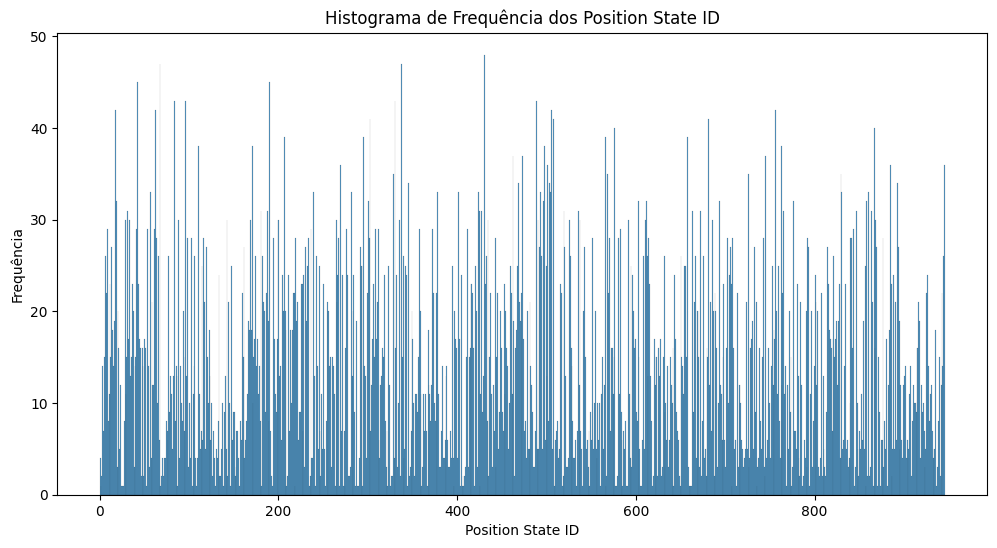

In [36]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.title('Histograma de Frequência dos Position State ID')
sns.histplot(df['position_state_id'],binwidth=1,)
plt.ylabel('Frequência')
plt.xlabel('Position State ID')
plt.show()

# Classes

In [37]:
def collate_masked_batch(batch, pad_token_id=0):
    xs, ys = zip(*batch)
    x = pad_sequence(xs, batch_first=True, padding_value=pad_token_id)
    y = pad_sequence(ys, batch_first=True, padding_value=-100)
    # attention_mask: 1 onde não é PAD
    attention_mask = (x != pad_token_id).long()
    return x, y, attention_mask

### dataset class

In [38]:
class TrajectoryARDataset_RandLen(Dataset):
    def __init__(
        self,
        full_sequence,
        min_len=4,
        max_len=32,
        bos_token_id=None,
        eos_token_id=None,
    ):
        """
        Autoregressivo: para cada janela, x = tokens[0..T-2], y = tokens[1..T-1].
        """
        assert min_len >= 2, "min_len precisa ser ≥ 2 para AR"
        self.full_sequence = list(full_sequence)
        if bos_token_id is not None:
            self.full_sequence = [bos_token_id] + self.full_sequence
        if eos_token_id is not None:
            self.full_sequence = self.full_sequence + [eos_token_id]

        self.min_len = min_len
        self.max_len = max_len

        # garante que ainda há pelo menos min_len tokens a partir de start
        self.start_indices = list(range(0, max(1, len(self.full_sequence) - self.min_len)))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))
        seq = self.full_sequence[start:end]

        # força pelo menos 2 tokens (raríssimo não cumprir devido à construção de start_indices)
        if len(seq) < 2:
            end = min(start + 2, len(self.full_sequence))
            seq = self.full_sequence[start:end]

        x = torch.tensor(seq[:-1], dtype=torch.long)  # input
        y = torch.tensor(seq[1:],  dtype=torch.long)  # alvo (próximo token)
        return x, y


In [39]:
class TrajectoryARDataset_FixLen(Dataset):
    def __init__(
        self,
        full_sequence,
        max_len=32,
        pad_token_id=947,
        bos_token_id=None,
        eos_token_id=None,
    ):
        self.full_sequence = list(full_sequence)

        if bos_token_id is not None:
            self.full_sequence = [bos_token_id] + self.full_sequence
        if eos_token_id is not None:
            self.full_sequence = self.full_sequence + [eos_token_id]

        self.max_len = max_len
        self.pad_token_id = pad_token_id

        self.start_indices = list(range(len(self.full_sequence)))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        end = start + self.max_len

        seq = self.full_sequence[start:end]

        if len(seq) < self.max_len:
            seq = seq + [self.pad_token_id] * (self.max_len - len(seq))

        x = torch.tensor(seq[:-1], dtype=torch.long)
        y = torch.tensor(seq[1:],  dtype=torch.long)
        return x, y

In [40]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe)  # não é treinável

    def forward(self, x):
        # x: [B, T, D]
        T = x.size(1)
        return x + self.pe[:T].unsqueeze(0)

### model class

In [41]:
class TrajectoryBERT_HardPos(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_layers,
        num_heads,
        hidden_dim,
        dropout=0.1,
        max_len=512,
        pad_token_id=0,
        causal=False,
    ):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_len = max_len
        self.causal = causal

        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=pad_token_id)
        self.position_embedding = PositionalEncoding(embed_size, max_len)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    @staticmethod
    def _causal_mask(T, device):
        return torch.triu(torch.ones(T, T, device=device, dtype=torch.bool), diagonal=1)

    def forward(self, x, attention_mask: torch.Tensor = None):
        """
        x: [B, T] com IDs de token
        attention_mask: [B, T], 1=valido, 0=PAD
        """
        B, T = x.size()
        device = x.device

        if T > self.max_len:
            x = x[:, -self.max_len:]
            T = self.max_len
            if attention_mask is not None:
                attention_mask = attention_mask[:, -self.max_len:]

        if attention_mask is None:
            key_padding_mask = (x == self.pad_token_id)
        else:
            key_padding_mask = (attention_mask == 0)
            if attention_mask.dtype == torch.bool:
                key_padding_mask = ~attention_mask

        h = self.embedding(x)
        h = self.position_embedding(h)

        src_mask = self._causal_mask(T, device) if self.causal else None

        h = self.encoder(h, mask=src_mask, src_key_padding_mask=key_padding_mask)
        logits = self.fc_out(h)
        return logits

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=50, eos_token_id=None, temperature=1.0, top_k=None):
        assert self.causal, "Ative causal=True para gerar de forma autoregressiva."
        self.eval()
        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        for _ in range(max_new_tokens):
            logits = self.forward(x)[:, -1, :]
            logits = logits / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                vals, idxs = torch.topk(logits, k=top_k, dim=-1)
                filt = torch.full_like(logits, float("-inf"))
                logits = filt.scatter(1, idxs, vals)

            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        return x.squeeze(0)

    @torch.no_grad()
    def generate_with_distributions(
        self,
        prompt_ids: torch.Tensor,
        max_new_tokens: int = 50,
        eos_token_id: int = None,
        temperature: float = 1.0,
        top_k: int = None,
        return_logits: bool = False,
        return_raw_logits: bool = False,
        to_cpu: bool = True,
    ):
        assert self.causal, "Ative causal=True para geração autoregressiva."
        self.eval()

        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        probs_list = []
        logits_list = [] if return_logits else None
        logits_raw_list = [] if return_raw_logits else None

        for _ in range(max_new_tokens):
            logits_raw = self.forward(x)[:, -1, :].squeeze(0)
            logits_adj = logits_raw / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                k = min(top_k, logits_adj.shape[-1])
                vals, idxs = torch.topk(logits_adj, k=k, dim=-1)
                tmp = torch.full_like(logits_adj, float("-inf"))
                logits_adj = tmp.scatter(0, idxs, vals)

            probs = torch.softmax(logits_adj, dim=-1)

            target_device = torch.device("cpu") if to_cpu else device
            probs_list.append(probs.detach().to(target_device))
            if return_logits:
                logits_list.append(logits_adj.detach().to(target_device))
            if return_raw_logits:
                logits_raw_list.append(logits_raw.detach().to(target_device))

            next_id = torch.multinomial(probs.unsqueeze(0), num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        out_tokens = x.squeeze(0)
        dists = {"probs": torch.stack(probs_list, dim=0)}
        if return_logits:
            dists["logits"] = torch.stack(logits_list, dim=0)
        if return_raw_logits:
            dists["logits_raw"] = torch.stack(logits_raw_list, dim=0)

        return out_tokens, dists

In [42]:
class TrajectoryBERTLearnedPos(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size,
        num_layers,
        num_heads,
        hidden_dim,
        dropout=0.1,
        max_len=512,
        pad_token_id=0,
        causal=False,
    ):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.max_len = max_len
        self.causal = causal

        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=pad_token_id)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    @staticmethod
    def _causal_mask(T, device):
        return torch.triu(torch.ones(T, T, device=device, dtype=torch.bool), diagonal=1)

    def forward(self, x, attention_mask: torch.Tensor = None):
        """
        x: [B, T] com IDs de token
        attention_mask: [B, T], 1=valido, 0=PAD
        """
        B, T = x.size()
        device = x.device

        if T > self.max_len:
            x = x[:, :self.max_len]
            T = self.max_len
            if attention_mask is not None:
                attention_mask = attention_mask[:, :self.max_len]

        if attention_mask is None:
            key_padding_mask = (x == self.pad_token_id)
        else:
            key_padding_mask = (attention_mask == 0)
            if attention_mask.dtype == torch.bool:
                key_padding_mask = ~attention_mask

        pos_ids = torch.arange(T, device=device).unsqueeze(0).expand(B, T)

        h = self.embedding(x) + self.position_embedding(pos_ids)

        src_mask = self._causal_mask(T, device) if self.causal else None

        h = self.encoder(h, mask=src_mask, src_key_padding_mask=key_padding_mask)
        logits = self.fc_out(h)
        return logits

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=50, eos_token_id=None, temperature=1.0, top_k=None):
        assert self.causal, "Ative causal=True para gerar de forma autoregressiva."
        self.eval()
        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        for _ in range(max_new_tokens):
            logits = self.forward(x)[:, -1, :]
            logits = logits / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                vals, idxs = torch.topk(logits, k=top_k, dim=-1)
                filt = torch.full_like(logits, float("-inf"))
                logits = filt.scatter(1, idxs, vals)

            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        return x.squeeze(0)

    @torch.no_grad()
    def generate_with_distributions(
        self,
        prompt_ids: torch.Tensor,
        max_new_tokens: int = 50,
        eos_token_id: int = None,
        temperature: float = 1.0,
        top_k: int = None,
        return_logits: bool = False,
        return_raw_logits: bool = False,
        to_cpu: bool = True,
    ):
        assert self.causal, "Ative causal=True para geração autoregressiva."
        self.eval()

        device = next(self.parameters()).device
        x = prompt_ids.to(device).unsqueeze(0)

        probs_list = []
        logits_list = [] if return_logits else None
        logits_raw_list = [] if return_raw_logits else None

        for _ in range(max_new_tokens):
            logits_raw = self.forward(x)[:, -1, :].squeeze(0)
            logits_adj = logits_raw / max(temperature, 1e-8)

            if top_k is not None and top_k > 0:
                k = min(top_k, logits_adj.shape[-1])
                vals, idxs = torch.topk(logits_adj, k=k, dim=-1)
                tmp = torch.full_like(logits_adj, float("-inf"))
                logits_adj = tmp.scatter(0, idxs, vals)

            probs = torch.softmax(logits_adj, dim=-1)

            target_device = torch.device("cpu") if to_cpu else device
            probs_list.append(probs.detach().to(target_device))
            if return_logits:
                logits_list.append(logits_adj.detach().to(target_device))
            if return_raw_logits:
                logits_raw_list.append(logits_raw.detach().to(target_device))

            next_id = torch.multinomial(probs.unsqueeze(0), num_samples=1)
            x = torch.cat([x, next_id], dim=1)

            if eos_token_id is not None and next_id.item() == eos_token_id:
                break

        out_tokens = x.squeeze(0)
        dists = {"probs": torch.stack(probs_list, dim=0)}
        if return_logits:
            dists["logits"] = torch.stack(logits_list, dim=0)
        if return_raw_logits:
            dists["logits_raw"] = torch.stack(logits_raw_list, dim=0)

        return out_tokens, dists

# Definitions

In [43]:
# Hiperparâmetros
embed_size = 16
num_layers = 1
num_heads = 1
hidden_dim = 32
mask_token_id = df['position_state_id'].max()
pad_token_id = df['position_state_id'].max() + 1
vocab_size = pad_token_id + 1
max_len = 100
dropout = 0.2
batch_size = 256
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 1e3
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 948)

In [44]:
max_len

100

In [45]:
sequences

array([864, 863,  67, ..., 132, 131, 133])

In [46]:
mask_token_id, pad_token_id

(946, 947)

# Model

### init datasets

In [47]:
# help(torch.utils.data.random_split)

In [48]:
# [Célula] Dataset e dataloaders
dataset = TrajectoryARDataset_FixLen(
    full_sequence=sequences,   # sua sequência única (lista de ids)
    max_len=max_len,           # seu valor existente
    bos_token_id=None,
    eos_token_id=None,
)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size], )

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)
val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
)

model_tag = 'HardPos'

In [49]:
model_tag

'HardPos'

# Train

In [54]:
runs_params = {}
    
# for i in range(2):
#     runs_params[f"max_len_100_run_{i:02d}"] = {'max_len':100}

# for i in range(5):
#     runs_params[f"max_len_50_run_{i:02d}"] = {'max_len':50}

for i in range(5):
    runs_params[f"max_len_5_run_{i:02d}"] = {'max_len':5}

runs_params

{'max_len_5_run_00': {'max_len': 5},
 'max_len_5_run_01': {'max_len': 5},
 'max_len_5_run_02': {'max_len': 5},
 'max_len_5_run_03': {'max_len': 5},
 'max_len_5_run_04': {'max_len': 5}}

In [55]:
run_results = {}

In [56]:
# [576, 568, 570, 569, 526, 525, 519, 514, 513][:10000]

## train loop

In [57]:
for run_tag, params in runs_params.items():
    print(run_tag, 'start')

    # Hiperparâmetros
    embed_size = 16
    num_layers = 1
    num_heads = 1
    hidden_dim = 32
    mask_token_id = df['position_state_id'].max()
    pad_token_id = df['position_state_id'].max() + 1
    vocab_size = pad_token_id + 1
    max_len = params['max_len']
    dropout = 0.2
    batch_size = 256
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_epochs = 1e3
    # Simulando dados
    sequences = df['position_state_id'].values

    device, vocab_size




    # [Célula] Dataset e dataloaders
    dataset = TrajectoryARDataset_FixLen(
        full_sequence=sequences,   # sua sequência única (lista de ids)
        max_len=max_len,           # seu valor existente
        bos_token_id=None,
        eos_token_id=None,
    )

    train_size = int(0.8 * len(dataset))
    val_size = len(dataset) - train_size
    train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size], )

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False,
        collate_fn=lambda b: collate_masked_batch(b, pad_token_id)
    )

    model_tag = f'HardPos+{run_tag}'
    # [Célula] Inicialização do modelo
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = TrajectoryBERT_HardPos(
        vocab_size,
        embed_size=embed_size,
        num_layers=num_layers,
        num_heads=num_heads,
        hidden_dim=hidden_dim,
        dropout=dropout,
        pad_token_id=pad_token_id,
        max_len=max_len,   # ajuste se necessário
        causal= True
    ).to(device)

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Trainable Params: {trainable_params}")


    # [Célula] Otimizador e critério
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
    # per-token para conseguirmos média apenas nos alvos válidos (-100 é ignorado)
    criterion = nn.CrossEntropyLoss(ignore_index=-100, reduction='none')

    # [Célula] Loop de treinamento
    train_losses, val_losses = [], []
    train_perplexities, val_perplexities = [], []

    for epoch in range(int(num_epochs)):
        model.train()
        train_nll_sum = 0.0
        train_tok_count = 0

        for x, y, attn in train_loader:
            x, y, attn = x.to(device), y.to(device), attn.to(device)

            optimizer.zero_grad()
            # pode passar a máscara (agora suportada), mas não é obrigatório
            logits = model(x, attention_mask=attn)

            # perda por token e média apenas onde y != -100
            loss_vec = criterion(logits.view(-1, vocab_size), y.view(-1))  # [B*T]
            valid = (y.view(-1) != -100)
            loss = loss_vec[valid].mean()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # opcional, ajuda na estabilidade
            optimizer.step()

            train_nll_sum += loss_vec[valid].sum().item()
            train_tok_count += valid.sum().item()

        # ---- validação ----
        model.eval()
        val_nll_sum = 0.0
        val_tok_count = 0
        with torch.no_grad():
            for x_val, y_val, attn_val in val_loader:
                x_val, y_val, attn_val = x_val.to(device), y_val.to(device), attn_val.to(device)
                val_logits = model(x_val, attention_mask=attn_val)

                v_loss_vec = criterion(val_logits.view(-1, vocab_size), y_val.view(-1))
                v_valid = (y_val.view(-1) != -100)
                val_nll_sum += v_loss_vec[v_valid].sum().item()
                val_tok_count += v_valid.sum().item()

        # perdas médias por token e perplexidade
        avg_train_loss = train_nll_sum / max(1, train_tok_count)
        avg_val_loss   = val_nll_sum   / max(1, val_tok_count)
        train_ppl = math.exp(avg_train_loss)
        val_ppl   = math.exp(avg_val_loss)

        train_losses.append(avg_train_loss);  val_losses.append(avg_val_loss)
        train_perplexities.append(train_ppl); val_perplexities.append(val_ppl)

        if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs or epoch==1:
            print(
                f"Epoch {epoch+1}/{num_epochs} | "
                f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
                f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}"
            )
            run_results[run_tag] = {
                'epoch': num_epochs,
                'avg_train_loss':avg_train_loss,
                'avg_train_ppl':train_ppl, 
                'avg_test_loss':avg_val_loss,
                'avg_test_ppl':val_ppl, 
            }


            save_coss_with_tag(model, f'{model_tag}_train_epoch_{epoch}')
            full_fwd_input = [576, 568, 570, 569, 526, 525, 519, 514, 513][:params['max_len']]
            full_fwd_training = snapshot_transformer_forward(model, full_fwd_input)
            with open(save_full_fwd_path(model_tag, f'full_fwd_train_epoch_{epoch}_{model_tag}'), 'wb') as fil:
                pickle.dump(full_fwd_training, fil)

    print(run_tag, 'end')

max_len_5_run_00 start
Total Trainable Params: 33508


/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Epoch 2/1000.0 | Train Loss: 7.0098 | Val Loss: 6.9790 | Train PPL: 1107.43 | Val PPL: 1073.83
Epoch 100/1000.0 | Train Loss: 5.0065 | Val Loss: 5.0568 | Train PPL: 149.37 | Val PPL: 157.09
Epoch 200/1000.0 | Train Loss: 3.4391 | Val Loss: 3.5957 | Train PPL: 31.16 | Val PPL: 36.44
Epoch 300/1000.0 | Train Loss: 2.5491 | Val Loss: 2.7631 | Train PPL: 12.79 | Val PPL: 15.85
Epoch 400/1000.0 | Train Loss: 2.0540 | Val Loss: 2.2972 | Train PPL: 7.80 | Val PPL: 9.95
Epoch 500/1000.0 | Train Loss: 1.7734 | Val Loss: 2.0275 | Train PPL: 5.89 | Val PPL: 7.59
Epoch 600/1000.0 | Train Loss: 1.5987 | Val Loss: 1.8563 | Train PPL: 4.95 | Val PPL: 6.40
Epoch 700/1000.0 | Train Loss: 1.4874 | Val Loss: 1.7375 | Train PPL: 4.43 | Val PPL: 5.68
Epoch 800/1000.0 | Train Loss: 1.4096 | Val Loss: 1.6494 | Train PPL: 4.09 | Val PPL: 5.20
Epoch 900/1000.0 | Train Loss: 1.3510 | Val Loss: 1.5784 | Train PPL: 3.86 | Val PPL: 4.85
Epoch 1000/1000.0 | Train Loss: 1.3051 | Val Loss: 1.5182 | Train PPL: 3.69 | 

In [58]:
run_results

{'max_len_5_run_00': {'epoch': 1000.0,
  'avg_train_loss': 1.3050562494702194,
  'avg_train_ppl': 3.68789653009691,
  'avg_test_loss': 1.5181908231749024,
  'avg_test_ppl': 4.563960709492156},
 'max_len_5_run_01': {'epoch': 1000.0,
  'avg_train_loss': 1.2803030505080062,
  'avg_train_ppl': 3.597729854238911,
  'avg_test_loss': 1.458171732669826,
  'avg_test_ppl': 4.298094275297917},
 'max_len_5_run_02': {'epoch': 1000.0,
  'avg_train_loss': 1.2751201850380647,
  'avg_train_ppl': 3.5791315423139847,
  'avg_test_loss': 1.4145118762750701,
  'avg_test_ppl': 4.1144776015929345},
 'max_len_5_run_03': {'epoch': 1000.0,
  'avg_train_loss': 1.2878850898041965,
  'avg_train_ppl': 3.625111657148244,
  'avg_test_loss': 1.45821244407163,
  'avg_test_ppl': 4.2982692603028685},
 'max_len_5_run_04': {'epoch': 1000.0,
  'avg_train_loss': 1.2729460621942084,
  'avg_train_ppl': 3.571358523477381,
  'avg_test_loss': 1.4291954781104277,
  'avg_test_ppl': 4.175338688933772}}

In [59]:
date_tag = datetime.now().strftime('%Y_%m_%d_%H_%M')
date_tag

'2026_06_14_00_03'

In [60]:
with open(notebook_run_path('span_loop', f'run_{date_tag}.pkl'), 'wb') as file:
    pickle.dump(run_results, file)

In [ ]:
# with open(notebook_run_path('span_loop', f'run_{date_tag}.pkl'), 'rb') as file:
#     runs_ = pickle.load(file)
# runs_

## results plot

In [ ]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
plt.yscale('log')
# plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]




set_epochs_to_plot = 50
# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(set_epochs_to_plot) + 1), train_losses[:set_epochs_to_plot], label='Train Loss')
plt.plot(range(1, int(set_epochs_to_plot) + 1), val_losses[:set_epochs_to_plot], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(set_epochs_to_plot) + 1), train_perplexities[:set_epochs_to_plot], label='Train Perplexity')
plt.plot(range(1, int(set_epochs_to_plot) + 1), val_perplexities[:set_epochs_to_plot], label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
plt.yscale('log')
# plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
dfml_metrics = pd.DataFrame()
dfml_metrics['epoch'] = [i+1 for i in range(len(train_losses))]
dfml_metrics['val_loss'] = [val for val in val_losses]
dfml_metrics['train_loss'] = [val for val in train_losses]
dfml_metrics['train_perplexity'] = [val for val in train_perplexities]
dfml_metrics['val_perplexity'] = [val for val in val_perplexities]

In [ ]:
dfml_metrics.head()

In [ ]:
len(train_losses), len(val_losses)

In [ ]:
save_ml_metrics = True

In [ ]:
if save_ml_metrics:
    dfml_metrics.to_csv(save_csv_path(model_tag, f'{model_tag}_train_metrics.csv'), index=False)

### save model

In [ ]:
save_model = True

In [ ]:
if save_model:
    torch.save(model.state_dict(), save_checkpoint_path(model_tag, f'gpt_model_{model_tag}.pt'))